

# COMPUTING INTELLIGENCE AND APPLICATIONS
## LAB 1: TELCO CUSTOMER CHURN ANALYSIS

**Registration Number:** 224004118

---

## 1 INTRODUCTION 

### 1.1 Introduction

This lab focuses on analyzing the Telco Customer Churn dataset using Python in a Kaggle Notebook. The main objective is to understand customer churn by performing data loading, preprocessing, and exploratory data analysis (EDA).

The first step involves loading the dataset and examining its structure. Data preprocessing is then performed by converting the Churn attribute from Yes/No to 1/0, checking and correcting data types, identifying missing values, and removing records containing null values.

The exploratory data analysis examines the relationship between customer churn and different attributes, including demographic characteristics (gender, senior citizen status, partner, and dependents), phone service subscriptions, contract types, paperless billing, and payment methods.

Python libraries such as Pandas, Matplotlib, and Seaborn are used to process, analyze, and visualize the dataset. The findings will help identify customer characteristics associated with churn and provide insights into customer retention.



---

## QUESTION 2: DATASET LOADING

### 2.1 Locate and Load the Dataset


In [76]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))


/kaggle/input/datasets/kwizerayves/telco-customer-churn-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv


**Observations:**

The CSV file was successfully located in the Kaggle input directory. Its file path will be used to load the Telco Customer Churn dataset into a Pandas DataFrame.

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file_path = "/kaggle/input/datasets/kwizerayves/telco-customer-churn-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


**Observations:**

The Telco Customer Churn dataset was successfully loaded into a Pandas DataFrame. Each row represents an individual customer, while the columns describe demographic information, subscribed services, payment characteristics, and churn status.


---

## QUESTION 3: DISPLAY DATASET 

### 3.1 Display the First Five and Last Five Records


In [61]:

# Display the first five records
print("First five rows:")
display(df.head())

# Display the last five records
print("Last five rows:")
display(df.tail())


First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Last five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


**Observations:**

The first five and last five records of the dataset were displayed successfully. The dataset contains customer demographic information, subscribed services, account details, and churn status. This initial inspection helps identify the available attributes and understand the structure of the data before preprocessing.

---

## QUESTION 4: DATA PREPROCESSING


In [62]:

# Display original values in the Churn column
print("Original Churn values:")
print(df["Churn"].value_counts())


Original Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


**Observation:** 

Before conversion, the dataset contains 5,174 customers who stayed with the company (No) and 1,869 customers who left (Yes). This shows that most customers did not churn. These categorical values will be converted into numerical values for easier analysis.

### 4.1 Convert Churn from Yes/No to 1/0

In [63]:
# Convert Churn from Yes/No to 1/0
df["Churn"] = df["Churn"].map(
    {"Yes": 1, "No": 0}
).astype(int)

# Display converted values
print("Churn values after conversion:")
print(df["Churn"].value_counts())

print("\nChurn data type:")
print(df["Churn"].dtype)


Churn values after conversion:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn data type:
int64


**Observations:**

The Churn attribute was successfully converted from Yes/No into numerical values, where 1 represents customers who left and 0 represents customers who stayed. The results show that 5,174 customers stayed while 1,869 customers churned. This conversion makes it easier to calculate churn rates and perform numerical analysis.


### 4.2 Examine and Correct Data Types

In [64]:
print("Data types before preprocessing:")
print(df.dtypes)

# Display detailed information
print("\nDataset information:")
df.info()


Data types before preprocessing:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 

In [65]:
# Convert TotalCharges from object to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)


print("Data types after conversion:")
print(df.dtypes)


Data types after conversion:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


**Observations:**

The data types of all attributes were examined. The TotalCharges attribute was converted from object to float64 because it represents numerical billing information. Any values that could not be converted were represented as missing values (NaN) so they could be identified and handled during data cleaning.

### 4.3 Identify Missing Values

In [66]:
missing_values = df.isnull().sum()

print("Missing values in each attribute:")
print(missing_values)


print("\nAttributes with missing values:")
print(missing_values[missing_values > 0])


print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values in each attribute:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Attributes with missing values:
TotalCharges    11
dtype: int64

Total missing values:
11


**Observation:**

The missing-value analysis shows that TotalCharges is the only attribute containing missing values, with 11 missing entries. All other attributes have zero missing values. These missing entries need to be handled before performing further analysis.

### 4.4 Remove Missing Values

In [67]:
print("Rows before removing null values:", df.shape[0])

# Remove rows containing missing values
df = df.dropna().copy()

print("Rows after removing null values:", df.shape[0])

# Verify that no null values remain
print("Remaining missing values:")
print(df.isnull().sum().sum())


Rows before removing null values: 7043
Rows after removing null values: 7032
Remaining missing values:
0


**Observations:**

After removing records containing missing values, the dataset decreased from 7,043 to 7,032 customers. A total of 11 records were removed, and the final check confirmed that no missing values remained. The cleaned dataset is now ready for exploratory data analysis.

---
## QUESTION 5: EXPLORATORY DATA ANALYSIS

### 5.1 Demographic Analysis

#### 5.1.1 Gender vs Churn

Gender and Churn Counts:


,Stayed,Churned
gender,,
Female,2544,939
Male,2619,930


Churn Rate by Gender (%):


gender
Female    26.96
Male      26.20
Name: Churn, dtype: float64

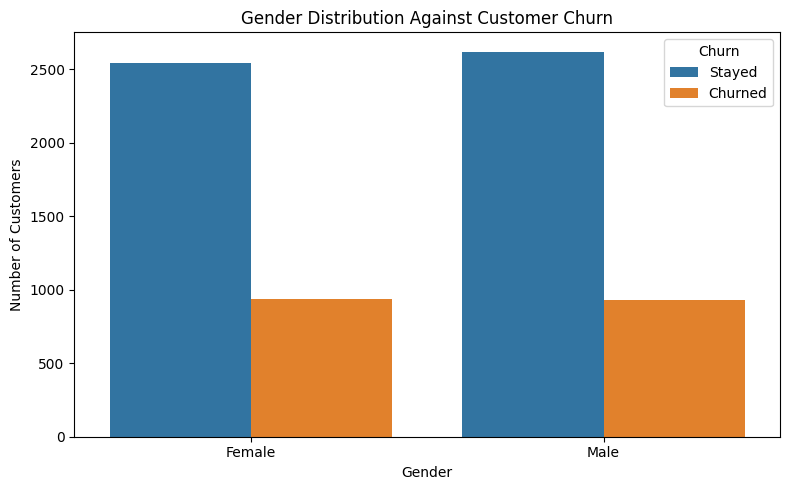

In [68]:

# Gender distribution against Churn

gender_counts = pd.crosstab(df["gender"], df["Churn"])
gender_counts.columns = ["Stayed", "Churned"]

print("Gender and Churn Counts:")
display(gender_counts)

# Calculate churn rate by gender
gender_rate = df.groupby("gender")["Churn"].mean() * 100

print("Churn Rate by Gender (%):")
display(gender_rate.round(2))

# Visualize gender distribution against Churn
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn",
    hue_order=[0, 1]
)

plt.title("Gender Distribution Against Customer Churn")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["Stayed", "Churned"])
plt.tight_layout()
plt.show()


**Observation:**

Female customers have a churn rate of 26.96%, while male customers have a churn rate of 26.20%. The difference is only 0.76 percentage points, indicating that churn rates are very similar across genders. Gender does not show a strong association with churn in this dataset.

#### 5.1.2 SeniorCitizen vs Churn


,Stayed,Churned
SeniorCitizen,,
0,4497,1393
1,666,476


Churn rate by SeniorCitizen (%):


SeniorCitizen
0    23.65
1    41.68
Name: Churn, dtype: float64

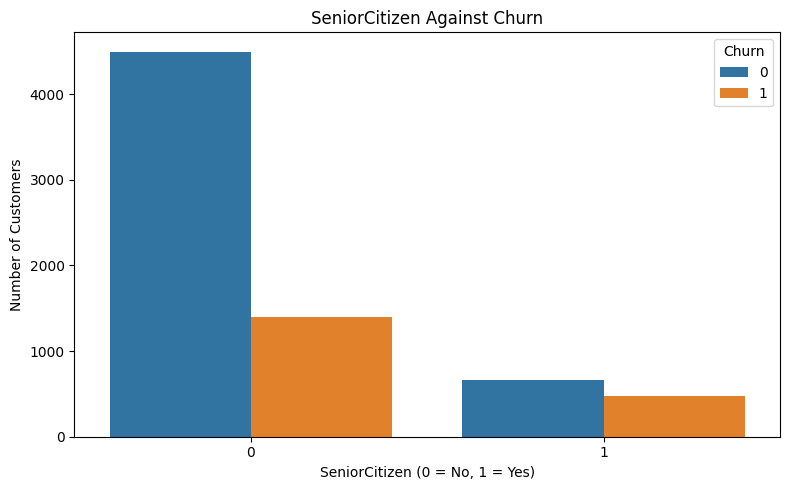

In [69]:
# SeniorCitizen against Churn

senior_counts = pd.crosstab(df["SeniorCitizen"], df["Churn"])
senior_counts.columns = ["Stayed", "Churned"]
display(senior_counts)

senior_rates = df.groupby("SeniorCitizen")["Churn"].mean() * 100

print("Churn rate by SeniorCitizen (%):")
display(senior_rates.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="SeniorCitizen", hue="Churn",
              hue_order=[0, 1])
plt.title("SeniorCitizen Against Churn")
plt.xlabel("SeniorCitizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:**

Senior citizens have a churn rate of 41.68%, compared with 23.65% for non-senior citizens. This shows that senior citizens have a substantially higher churn rate, suggesting an association between senior citizen status and customer churn.


#### 5.1.3 Partner vs Churn

,Stayed,Churned
Partner,,
No,2439,1200
Yes,2724,669


Churn rate by Partner (%):


Partner
No     32.98
Yes    19.72
Name: Churn, dtype: float64

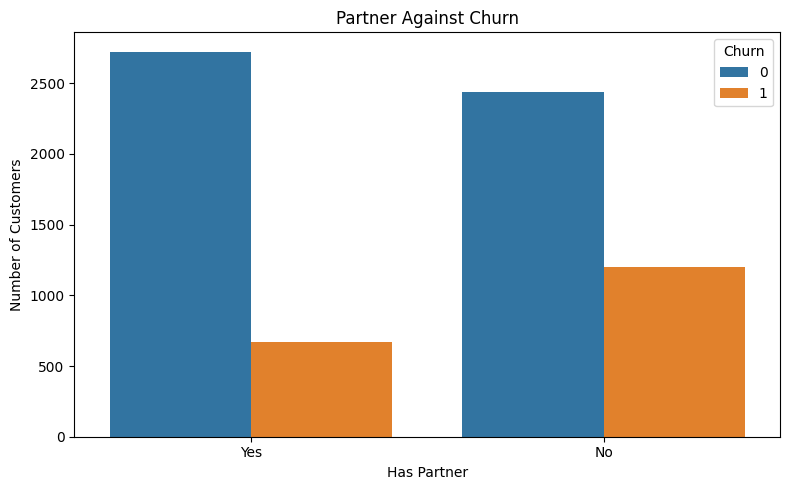

In [70]:
partner_counts = pd.crosstab(df["Partner"], df["Churn"])
partner_counts.columns = ["Stayed", "Churned"]
display(partner_counts)

partner_rates = df.groupby("Partner")["Churn"].mean() * 100

print("Churn rate by Partner (%):")
display(partner_rates.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Partner", hue="Churn",
              hue_order=[0, 1])
plt.title("Partner Against Churn")
plt.xlabel("Has Partner")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:**

Customers without partners have a churn rate of 32.98%, while customers with partners have a churn rate of 19.72%. This indicates that customers without partners are more likely to churn in the observed dataset.


#### 5.1.4 Dependents vs Churn

,Stayed,Churned
Dependents,,
No,3390,1543
Yes,1773,326


Churn rate by Dependents (%):


Dependents
No     31.28
Yes    15.53
Name: Churn, dtype: float64

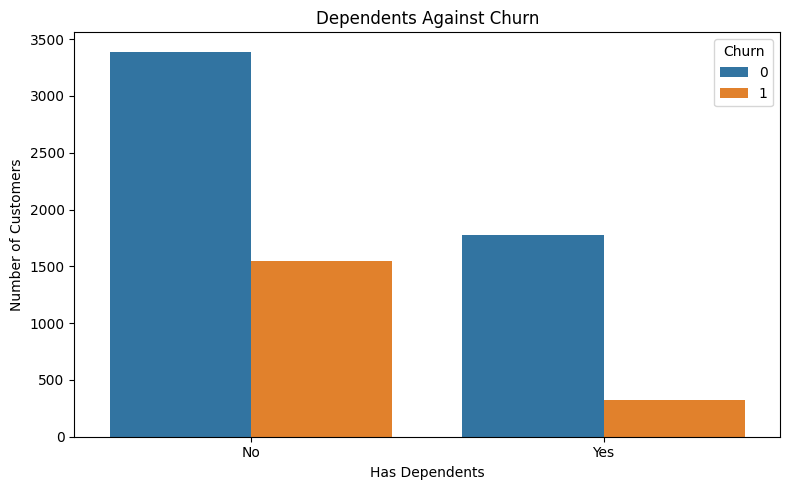

In [71]:
# Dependents against Churn

dependent_counts = pd.crosstab(df["Dependents"], df["Churn"])
dependent_counts.columns = ["Stayed", "Churned"]
display(dependent_counts)

dependent_rates = df.groupby("Dependents")["Churn"].mean() * 100

print("Churn rate by Dependents (%):")
display(dependent_rates.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Dependents", hue="Churn",
              hue_order=[0, 1])
plt.title("Dependents Against Churn")
plt.xlabel("Has Dependents")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:** 

Customers without dependents have a churn rate of 31.28%, compared with 15.53% for customers with dependents. This suggests that customers with dependents tend to remain with the company more frequently than those without dependents.

### 5.2 Service Analysis

#### 5.2.1 PhoneService vs Churn

,Stayed,Churned
PhoneService,,
No,510,170
Yes,4653,1699


Churn rate by PhoneService (%):


PhoneService
No     25.00
Yes    26.75
Name: Churn, dtype: float64

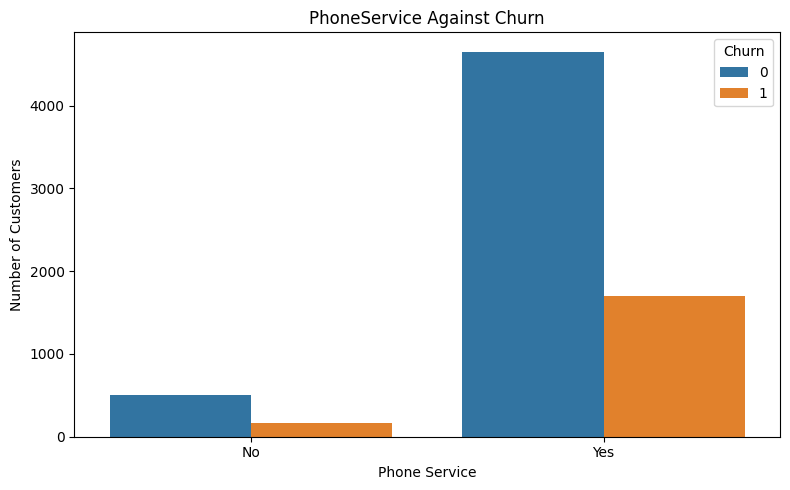

In [72]:
# PhoneService against Churn

phone_counts = pd.crosstab(df["PhoneService"], df["Churn"])
phone_counts.columns = ["Stayed", "Churned"]
display(phone_counts)

phone_rates = df.groupby("PhoneService")["Churn"].mean() * 100

print("Churn rate by PhoneService (%):")
display(phone_rates.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="PhoneService", hue="Churn",
              hue_order=[0, 1])
plt.title("PhoneService Against Churn")
plt.xlabel("Phone Service")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:** 

Customers with phone service have a churn rate of 26.75%, while customers without phone service have a churn rate of 25.00%. The difference is relatively small, suggesting that phone service subscription alone is not strongly associated with churn in this dataset.

### 5.3 Payment Analysis

#### 5.3.1 Contract vs Churn

,Stayed,Churned
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


Churn rate by Contract (%):


Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

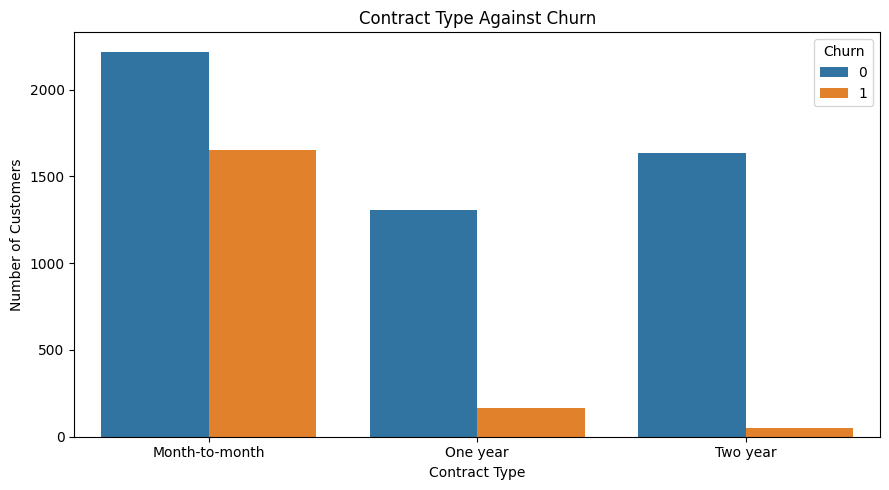

In [73]:
# Contract against Churn

contract_counts = pd.crosstab(df["Contract"], df["Churn"])
contract_counts.columns = ["Stayed", "Churned"]
display(contract_counts)

contract_rates = df.groupby("Contract")["Churn"].mean() * 100

print("Churn rate by Contract (%):")
display(contract_rates.round(2))

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Contract", hue="Churn",
              hue_order=[0, 1])
plt.title("Contract Type Against Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:** 

Customers with month-to-month contracts have the highest churn rate at 42.71%, followed by one-year contracts at 11.28%. Customers with two-year contracts have the lowest churn rate at 2.85%. This shows a strong association between longer contract duration and lower customer churn.

#### 5.3.2 PaperlessBilling vs Churn

,Stayed,Churned
PaperlessBilling,,
No,2395,469
Yes,2768,1400


Churn rate by PaperlessBilling (%):


PaperlessBilling
No     16.38
Yes    33.59
Name: Churn, dtype: float64

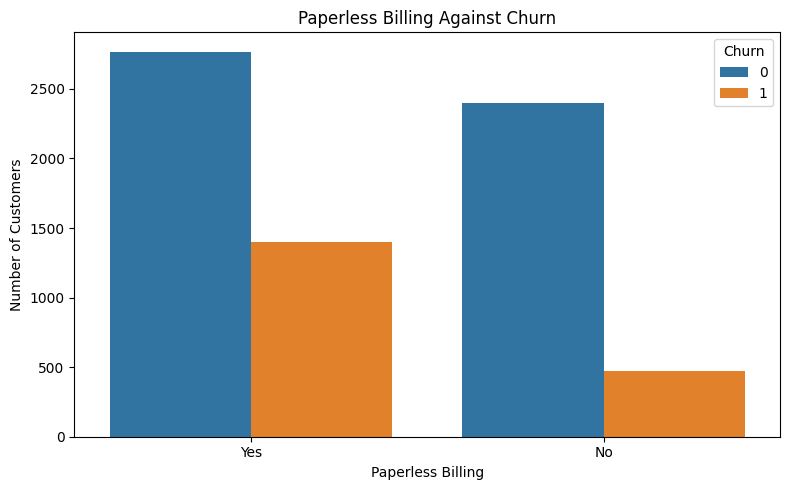

In [74]:
# PaperlessBilling against Churn

billing_counts = pd.crosstab(df["PaperlessBilling"], df["Churn"])
billing_counts.columns = ["Stayed", "Churned"]
display(billing_counts)

billing_rates = df.groupby("PaperlessBilling")["Churn"].mean() * 100

print("Churn rate by PaperlessBilling (%):")
display(billing_rates.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="PaperlessBilling", hue="Churn",
              hue_order=[0, 1])
plt.title("Paperless Billing Against Churn")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**Observation:**

Customers using paperless billing have a churn rate of 33.59%, while those not using paperless billing have a churn rate of 16.38%. This indicates that customers using paperless billing are associated with a higher churn rate. However, this does not establish that paperless billing causes customers to leave.


#### 5.3.3 PaymentMethod vs Churn

,Stayed,Churned
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308


Churn rate by PaymentMethod (%):


PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
Name: Churn, dtype: float64

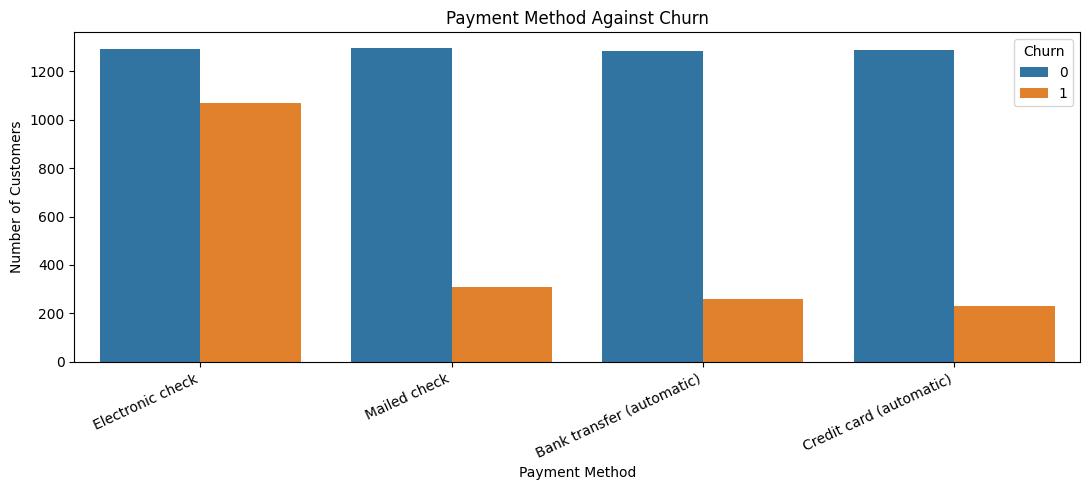

In [75]:
# PaymentMethod against Churn

payment_counts = pd.crosstab(df["PaymentMethod"], df["Churn"])
payment_counts.columns = ["Stayed", "Churned"]
display(payment_counts)

payment_rates = df.groupby("PaymentMethod")["Churn"].mean() * 100

print("Churn rate by PaymentMethod (%):")
display(payment_rates.round(2))

plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn",
              hue_order=[0, 1])
plt.title("Payment Method Against Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


**Observation:**

Customers using electronic checks have the highest churn rate at 45.29%, followed by mailed checks at 19.20% and automatic bank transfers at 16.73%. Automatic credit card payments have the lowest churn rate at 15.25%. This suggests that payment method is associated with churn, with electronic check users showing a particularly high churn rate.

##  Conclusion

In this lab, the Telco Customer Churn dataset was successfully loaded, preprocessed, and analyzed using Python. The Churn attribute was converted from Yes/No to 1/0, the TotalCharges data type was corrected, and 11 records containing missing values were removed, leaving 7,032 customer records for analysis.

The exploratory data analysis revealed that customers with month-to-month contracts had a high churn rate of 42.71%, while those with two-year contracts had a much lower rate of 2.85%. Customers using electronic checks also showed a high churn rate of 45.29%. Senior citizens, customers without partners, and customers without dependents had higher churn rates than their respective comparison groups. In contrast, gender and phone service showed relatively small differences in churn rates.

Overall, the analysis identified several customer characteristics associated with churn, particularly contract type and payment method. These findings can help the company understand customer behavior and identify groups that may need greater attention to improve customer retention.